# Trajectory Evaluation Walkthrough

This notebook compares two visual SLAM estimates (ORB-SLAM and S-PTAM) of a KITTI sequence against the ground truth:

1. load trajectories (trajectopy, TUM, KITTI and EuRoC files and ROS bags are recognized automatically),
2. compute the absolute (ATE) and relative (RPE) trajectory error,
3. compare the estimates in a summary table, including confidence intervals that account for the temporal correlation of the deviations,
4. look at the accuracy in segments of the trajectory,
5. plot the results and write a self-contained HTML report.

Run it from the repository root with `pip install "trajectopy[plot]"`.

In [1]:
import os
import sys

if sys.platform.startswith("linux") and not os.environ.get("DISPLAY"):
    os.environ.setdefault("QT_QPA_PLATFORM", "offscreen")  # render the figures without a display
if os.path.basename(os.getcwd()) == "example_scripts":
    os.chdir("..")  # the example data is in the repository root

import trajectopy as tpy

reference = tpy.Trajectory.from_file("./example_data/KITTI_gt.traj")
estimates = [tpy.Trajectory.from_file(f"./example_data/KITTI_{name}.traj") for name in ("ORB", "SPTAM")]
print(reference)


 _______________________________________________________
| ------------------ Trajectory Info ------------------ |
| Name:                         KITTI Ground Truth      |
| Number of poses:              4541                    |
| Orientation available:        yes                     |
| EPSG:                         0                       |
| Length [m]:                   3724.187                |
| Data rate [Hz]:               1.000                   |
| Function of:                  time [s]                |
|_______________________________________________________|



## Absolute and relative trajectory error

`ate` aligns each estimate to the reference first (similarity transformation by default).

In [2]:
ate_results = [tpy.ate(estimate, reference) for estimate in estimates]
rpe_results = [tpy.rpe(estimate, reference) for estimate in estimates]

for result in ate_results:
    low, high = result.confidence_interval("position", "mean")
    print(
        f"{result.name}: ATE {result.pos_ate:.3f} m (95% CI {low:.3f} - {high:.3f} m), 95th percentile {result.pos_dev_p95:.3f} m"
    )

KITTI ORB vs. KITTI Ground Truth: ATE 1.153 m (95% CI 0.842 - 1.356 m), 95th percentile 2.224 m
KITTI SPTAM vs. KITTI Ground Truth: ATE 3.489 m (95% CI 2.494 - 3.898 m), 95th percentile 5.361 m


## Summary table

One row per result. The confidence intervals come from a block bootstrap whose blocks are as long as the correlation of the deviations, so they are much wider (and more honest) than `std / sqrt(n)`. `format_table` writes the table as Markdown, CSV or LaTeX.

In [3]:
table = tpy.summary_table(ate_results, rpe_results)
table.T

name,KITTI ORB vs. KITTI Ground Truth,KITTI SPTAM vs. KITTI Ground Truth
poses,4541,4541
pos_mean [m],1.153277,3.489183
pos_median [m],1.032517,3.641255
pos_rms [m],1.304271,3.738536
pos_std [m],0.609159,1.342482
pos_p95 [m],2.224224,5.361007
pos_max [m],3.638287,7.789704
pos_mean_ci_low [m],0.841816,2.493526
pos_mean_ci_high [m],1.356227,3.898101
pos_rms_ci_low [m],0.950906,2.686143


In [4]:
print(tpy.format_table(table[["pos_mean [m]", "pos_rms [m]", "pos_p95 [m]", "pos_drift"]], "markdown"))

| name | pos_mean [m] | pos_rms [m] | pos_p95 [m] | pos_drift |
| --- | --- | --- | --- | --- |
| KITTI ORB vs. KITTI Ground Truth | 1.1533 | 1.3043 | 2.2242 | 0.6945 |
| KITTI SPTAM vs. KITTI Ground Truth | 3.4892 | 3.7385 | 5.3610 | 1.4623 |



## Accuracy along the trajectory

`segment_statistics` splits the deviations into windows of time or path length, or by labels of your own (e.g. tunnel / open sky).

In [5]:
ate_results[0].segment_statistics(segment_length=500, by="path_length").round(3)

,segment,start,end,count,pos_mean,pos_median,pos_rms,pos_p95,pos_max,rot_mean,rot_rms,rot_max
0,0,0.000,499.955,719,0.871,0.668,1.055,2.102,3.638,0.745,0.857,2.102
1,1,500.529,999.825,704,1.121,1.022,1.146,1.515,1.620,0.484,0.518,0.936
2,2,1000.474,1499.236,601,1.556,1.722,1.672,2.278,2.406,0.826,1.055,6.570
3,3,1500.251,1999.238,610,0.881,0.853,0.946,1.583,1.918,0.528,0.575,1.933
4,4,2000.308,2498.999,589,0.672,0.529,0.749,1.271,1.364,0.658,0.992,6.747
5,5,2500.111,2999.638,610,0.912,0.726,1.012,1.632,1.694,0.515,0.536,0.843
6,6,3000.714,3498.712,471,1.846,1.765,1.854,2.128,2.276,0.603,0.636,0.936
7,7,3500.025,3705.098,237,2.224,2.432,2.248,2.534,2.561,0.576,0.602,0.896


## Figures

The same figures as in the GUI. Here, they are exported to PNG files and displayed; `vis.show(figures)` opens them in an interactive window instead.

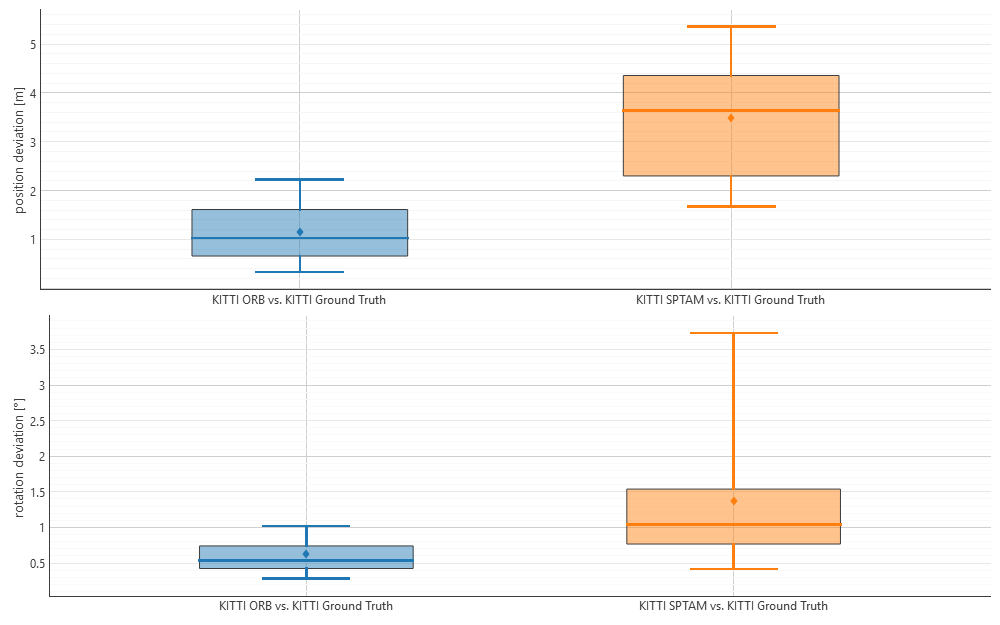

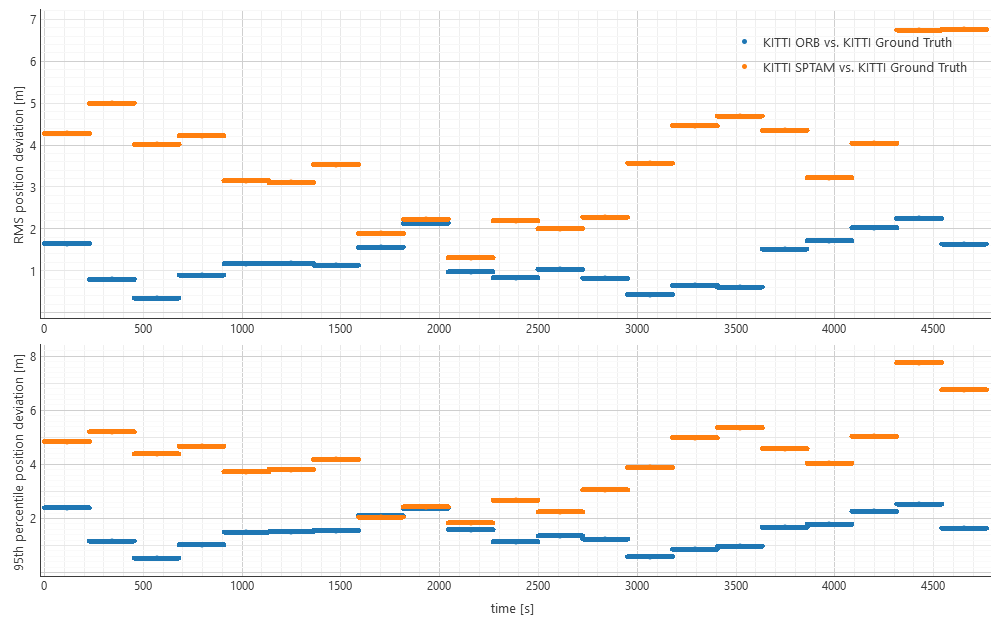

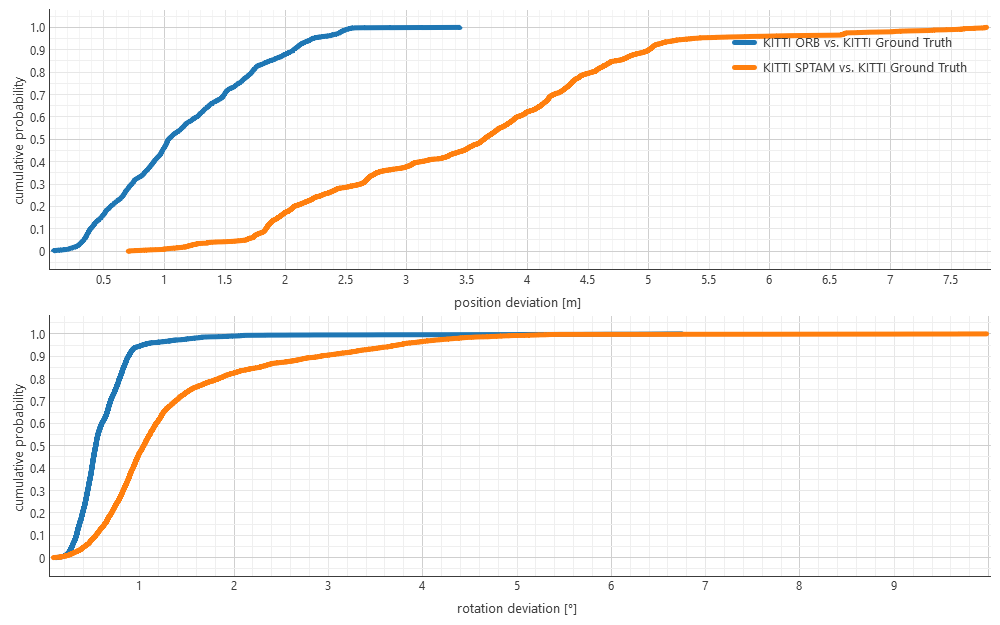

In [6]:
import tempfile

from IPython.display import Image, display

from trajectopy import visualization as vis

figures = [
    vis.ate_boxplot_figure(ate_results),
    vis.ate_distribution_figure(ate_results),
]
with tempfile.TemporaryDirectory() as directory:
    for path in vis.export_figures(figures, directory, width=1000):
        display(Image(filename=path))

## Report

A single HTML file with the summary, the statistics of each result, all figures and the processing settings. The command line does the same: `trajectopy evaluate example_data/KITTI_ORB.traj example_data/KITTI_SPTAM.traj --ref example_data/KITTI_gt.traj --report reports/report.html`.

In [7]:
os.makedirs("reports", exist_ok=True)
tpy.write_report(
    "reports/report.html", ate_results=ate_results, rpe_results=rpe_results, settings=tpy.ProcessingSettings()
)
print(f"reports/report.html: {os.path.getsize('reports/report.html') / 1e6:.1f} MB")

reports/report.html: 2.3 MB
